**Student Name:** Temuulen Batsaikhan

**Student Number:** 8252026

**Lecturer:** Taufique Ahmed

**Module:** Data Visualisation and Communication

**Assessment:** CA1 — AI Employment Data Visualisation

**College:** CCT College Dublin

**Dataset:** US Bureau of Labor Statistics May 2023

**GitHub:** https://github.com/Temuulen-BCS/Data-Visualisation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel(
    "all_data_M_2023.xlsx",
    sheet_name="All May 2023 data",
    usecols=[
        "AREA_TYPE",
        "AREA_TITLE",
        "NAICS",
        "OCC_CODE",
        "OCC_TITLE",
        "O_GROUP",
        "TOT_EMP",
        "A_MEAN"
    ]
)

print(df.shape)
df.head()

(413327, 8)


,AREA_TITLE,AREA_TYPE,NAICS,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,A_MEAN
0,U.S.,1,000000,00-0000,All Occupations,total,151853870,65470
1,U.S.,1,000000,11-0000,Management Occupations,major,10495770,137750
2,U.S.,1,000000,11-1000,Top Executives,minor,3751510,136100
3,U.S.,1,000000,11-1010,Chief Executives,broad,211230,258900
4,U.S.,1,000000,11-1011,Chief Executives,detailed,211230,258900


In [3]:
occupations = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information Research Scientists",
    "Information Security Analysts",
    "Computer Programmers"]

df["NAICS"] = pd.to_numeric(df["NAICS"], errors="coerce")
df["TOT_EMP"] = pd.to_numeric(df["TOT_EMP"], errors="coerce")
df["A_MEAN"] = pd.to_numeric(df["A_MEAN"], errors="coerce")

filtered_data = df[
    (df["NAICS"] == 0) &
    (df["O_GROUP"] == "detailed") &
    (df["OCC_TITLE"].isin(occupations))].copy()

national_data = filtered_data[
    filtered_data["AREA_TITLE"] == "U.S."].copy()

state_data = filtered_data[
    filtered_data["AREA_TYPE"] == 2].copy()

print("National records:", len(national_data))
print("State records:", len(state_data))
national_data[["OCC_TITLE", "TOT_EMP", "A_MEAN"]]

National records: 5
State records: 246


,OCC_TITLE,TOT_EMP,A_MEAN
136,Information Security Analysts,175350.0,124740.0
138,Computer and Information Research Scientists,35210.0,157160.0
148,Computer Programmers,120370.0,107750.0
149,Software Developers,1656880.0,138110.0
165,Data Scientists,192710.0,119040.0


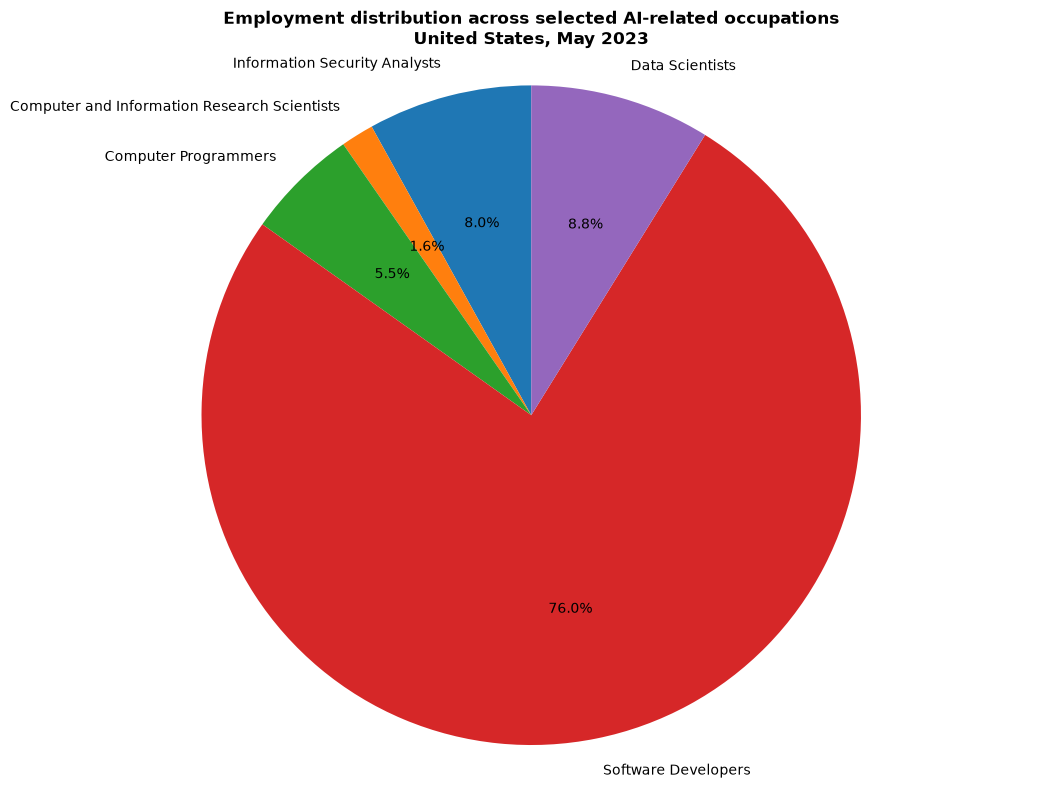

In [4]:
pie_data = national_data.dropna(subset=["TOT_EMP"])

plt.figure(figsize=(11, 8))
plt.pie(
    pie_data["TOT_EMP"],
    labels=pie_data["OCC_TITLE"],
    autopct="%1.1f%%",
    startangle=90)

plt.title(
    "Employment distribution across selected AI-related occupations\n"
    "United States, May 2023",
    fontweight="bold")

plt.axis("equal")
plt.tight_layout()
plt.show()

Visualisation shows employment distribution across selected AI occupations in May 2023 

Objective:  

This pie chart's objective is to investigate how employment is distributed across five occupations such as Artificial Intelligence, Data Science and Software Developer in the United States in May 2023. The visualisation compares amount of people that are in specific occupation to see how many percentages of people are in those jobs. To show this I chose pie chart because it is useful for showing which job takes how much of the job market. The dataset contains categorical data and numerical data meaning pie chart is perfect to showcase such data. This will allow any readers to understand each occupation size compared to each other in the job market. 

What we can see from the chart: 

The pie chart shows that Software developers are the largest group that are employed for accounting 76 percent of the market in those 5 occupations. This is way higher than next most employed occupations such as Data Scientists 8.8 percent and Security Analysts 8 percent. Thus, leaving the least employed jobs Computer Programmers 5.5 percent and Computer Research Scientists 1.6 percent meaning the least occupied job in the United States. This shows that Software Developer less skilled job between 5 of them is most occupied and more skilled job like Computer and information research scientists are least employed. However, this doesn't really show if the software developer uses AI for their work. The occupational categories only show how much people are employed in such job occupations and not necessarily if they are working with or developing AI for their work. 

In conclusion: 

The visualisation demonstrates that employment rate is unevenly distributed across jobs in high technology works. Software developer holds the highest percentage representing the biggest population, while more skilled profession is way smaller than we expected. This provides a useful starting point for investigation going forward between AI related employment that we would be looking into.  

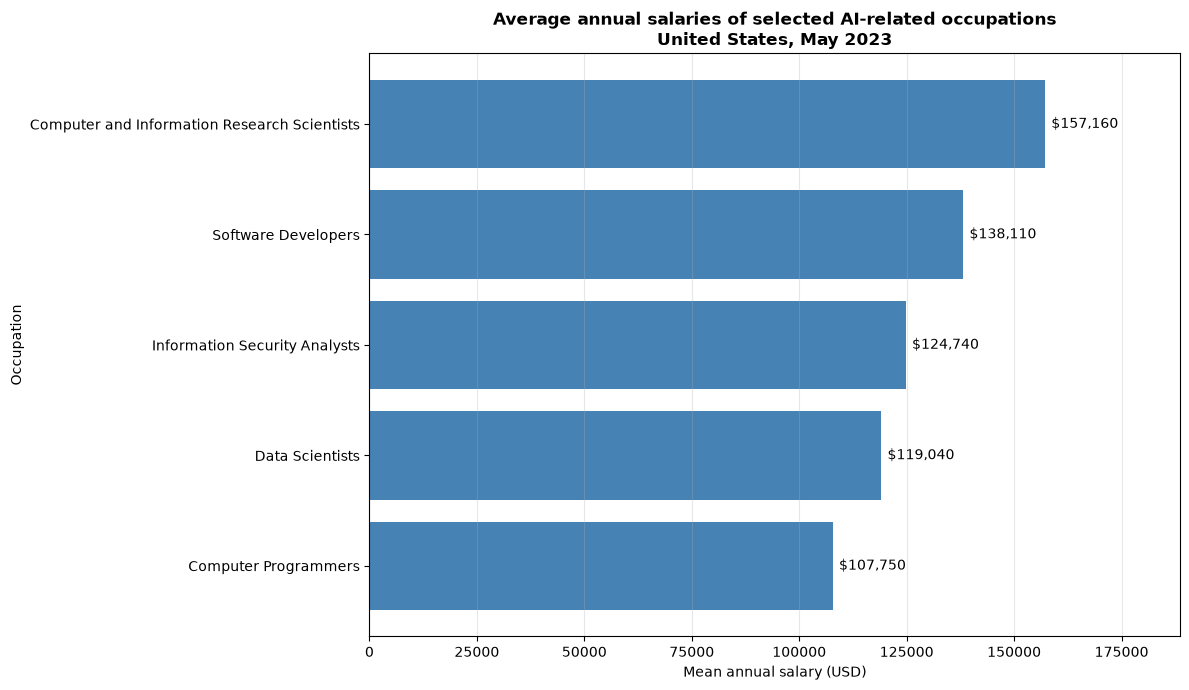

In [5]:
salary_data = national_data.sort_values("A_MEAN")
plt.figure(figsize=(12, 7))
plt.barh(
    salary_data["OCC_TITLE"],
    salary_data["A_MEAN"],
    color="steelblue")

for i, salary in enumerate(salary_data["A_MEAN"]):
    plt.text(
        salary + 1500,
        i,
        f"${salary:,.0f}",
        va="center")

plt.title(
    "Average annual salaries of selected AI-related occupations\n"
    "United States, May 2023",
    fontweight="bold")

plt.xlabel("Mean annual salary (USD)")
plt.ylabel("Occupation")
plt.xlim(0, salary_data["A_MEAN"].max() * 1.2)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Visualisation 2 average salaries of AI related jobs in 2023 

Objective: 

This visualisation shows the comparison between the 5 jobs and their annual salaries in the United States in May 2023. I wanted to investigate which jobs have the highest or the lowest salaries in the occupations to see if the more employees also have high earnings. The reason why I chose horizontal bar chart is comparing numerical data between the datasets is easier. The occupations are categorical data, while salaries are numerical meaning horizontal bars also make occupation data easier to read. I also sorted the bars by salary so differences will be easier to take in. 

Findings and what we can understand: 

From the chart we can see that Computer and information research scientists have the highest average annual salary at 157160 dollars, while software developers at 138110 dollars. Other jobs at Information Security analysts 124740 dollars, data scientists 119040 dollars, computer programmers 107750 dollars. The difference between the highest and the lowest earning jobs are 49410 dollars, showing that there are notable gaps in job occupation. If we compare this chart to first chart highest occupied job Software developer is not the highest earning job, while computer information research scientists that represent only 1.6 percent of the job market earns that highest amount of salary. 

In conclusion: 

This bar chart shows that average annual salaries are different between the occupations. Computer and information research scientists have the highest, on the other hand Computer programmers have the lowest salaries in those 5 occupations. While comparing it to first chart there is noticeable difference in salary and amount of people working for the job.

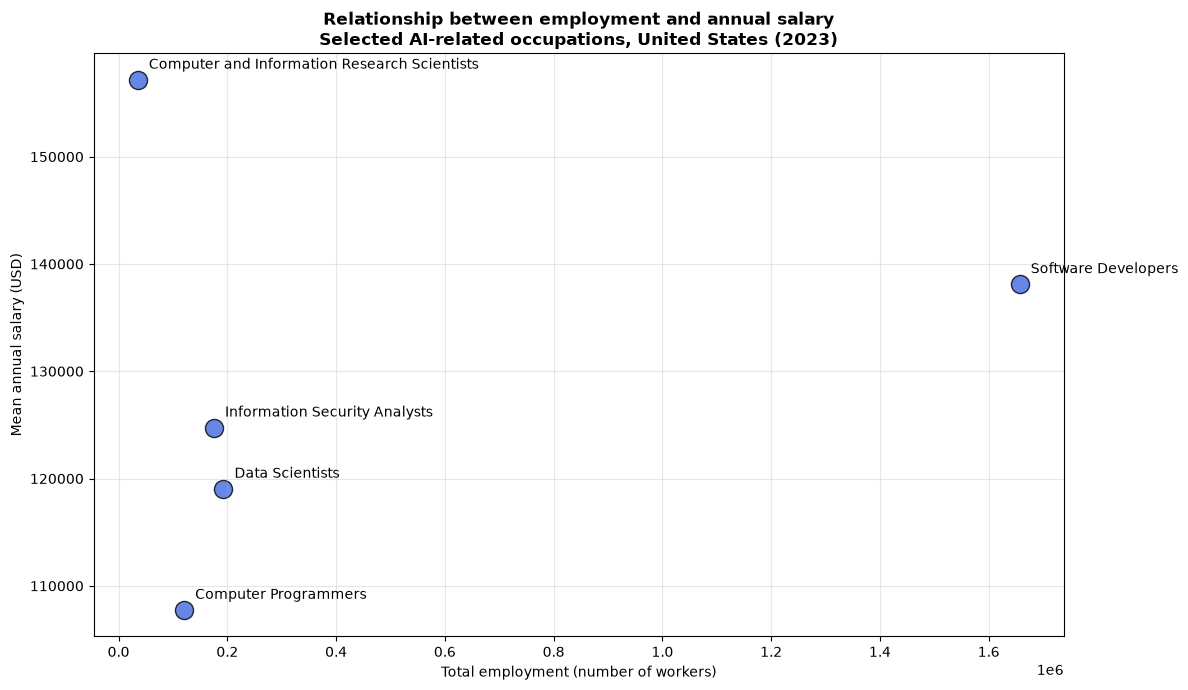

In [6]:
scatter_data = national_data.dropna(
    subset=["TOT_EMP", "A_MEAN"])

plt.figure(figsize=(12, 7))

plt.scatter(
    scatter_data["TOT_EMP"],
    scatter_data["A_MEAN"],
    s=170,
    color="royalblue",
    edgecolors="black",
    alpha=0.8)

for _, row in scatter_data.iterrows():
    plt.annotate(
        row["OCC_TITLE"],
        (row["TOT_EMP"], row["A_MEAN"]),
        xytext=(8, 8),
        textcoords="offset points")

plt.title(
    "Relationship between employment and annual salary\n"
    "Selected AI-related occupations, United States (2023)",
    fontweight="bold")

plt.xlabel("Total employment (number of workers)")
plt.ylabel("Mean annual salary (USD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Visualisation 3 comparison between employment and salary 

Objective:  

This scatter plot will visualize relation between total employment and average annual salary between the five Ai related jobs in United States 2023. From this I wanted to understand does having higher employment meant higher salary or lower salary.  This scatter plot will help me understand this question better because there are two numerical variables in this data. Each dots represents one occupation and where it stands showcase the total employment and total salary count. This makes it so that we can understand the data through pattern recognition. But in this data, there is one considerable outlier in this chart and that is Software Developer. 

Findings and what we can understand: 

The scatter plot has few interesting information that we can instantly see such as Software developer with the highest employment with 1.66 million workers and 138110 dollars salary. Computer and information research scientists have much lower employment with 35210 dollars but the highest salary of 157160 dollars.  These findings show higher employment does not correlate to higher salary. The opposite less workers there are in the occupations higher the salary will be, but there is only one outlier and that is Software developer. 

In conclusion: 

The scatter plot shows that employment size is not great indicator to find out the salary size. Other factors might be in play to impact the amount of salary workers get in the occupations like job responsibilities, qualification and specialised skill. Meaning further research is needed to find out such factors. 

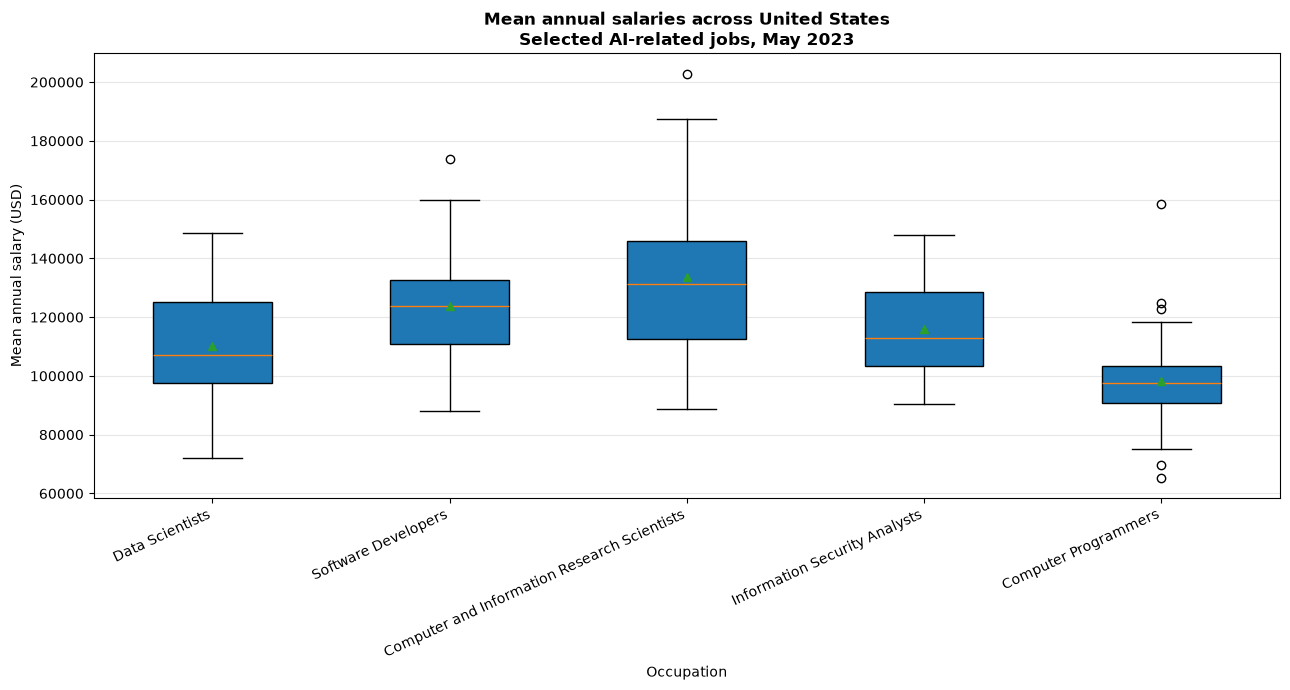

In [7]:
box_data = state_data.dropna(subset=["A_MEAN"])

salary_groups = [
    box_data.loc[
        box_data["OCC_TITLE"] == occupation,
        "A_MEAN" ].values for occupation in occupations]

plt.figure(figsize=(13, 7))
plt.boxplot(
    salary_groups,
    tick_labels=occupations,
    patch_artist=True,
    showmeans=True)

plt.title(
    "Mean annual salaries across United States\n"
    "Selected AI-related jobs, May 2023",
    fontweight="bold")

plt.xlabel("Occupation")
plt.ylabel("Mean annual salary (USD)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Visualisation 4 Distribution of annual salaries in United States of America 

Objective: 

The visual data demonstrates that mean annual salaries vary between five different jobs in the United States. These jobs are all related to AI, Data science and software development one way or another thus, I wanted to compare state salary for each occupation and identify which occupation have the biggest difference between them. To do that I used Box Plot for my research because it is useful when comparing distribution of numerical values across different categories. Unlike the bar chart this chart shows median, quartiles, spread and potential outliers in the state level mean salaries. This allows me to show that variation between the occupations focusing on single figure. 

Findings and what we can understand: 

Box Plot shows that Computer and Information Research Scientists have the highest median salary at around 131000 dollars. This job also has the highest interquartile range meaning average salaries vary very differently between states. Software developers are the second highest median after CIRS with 124000 dollars but, has big outliers going high as 174000 dollars. Information security analysts have median of 113000 dollars; data scientists have median of 107000 dollars; Computer programmers have the lowest median with 97000 dollars. However, if you see closely on computer programmer you can find out that this has both low and high outlier while others have only high outlier. This means geographical location of employment is connected to difference in salaries earned. However, only downside to this chart is this doesn't explain why this differences exist. 

In conclusion:  

This Box Plot chart shows that average annual salaries vary between US states and across five occupations. Computer and information research scientists have the highest median state salary, while computer programmers have the lowest median salaries. This visual data provides different perspective from national salary comparison to geographical differences in analysing technology employment.

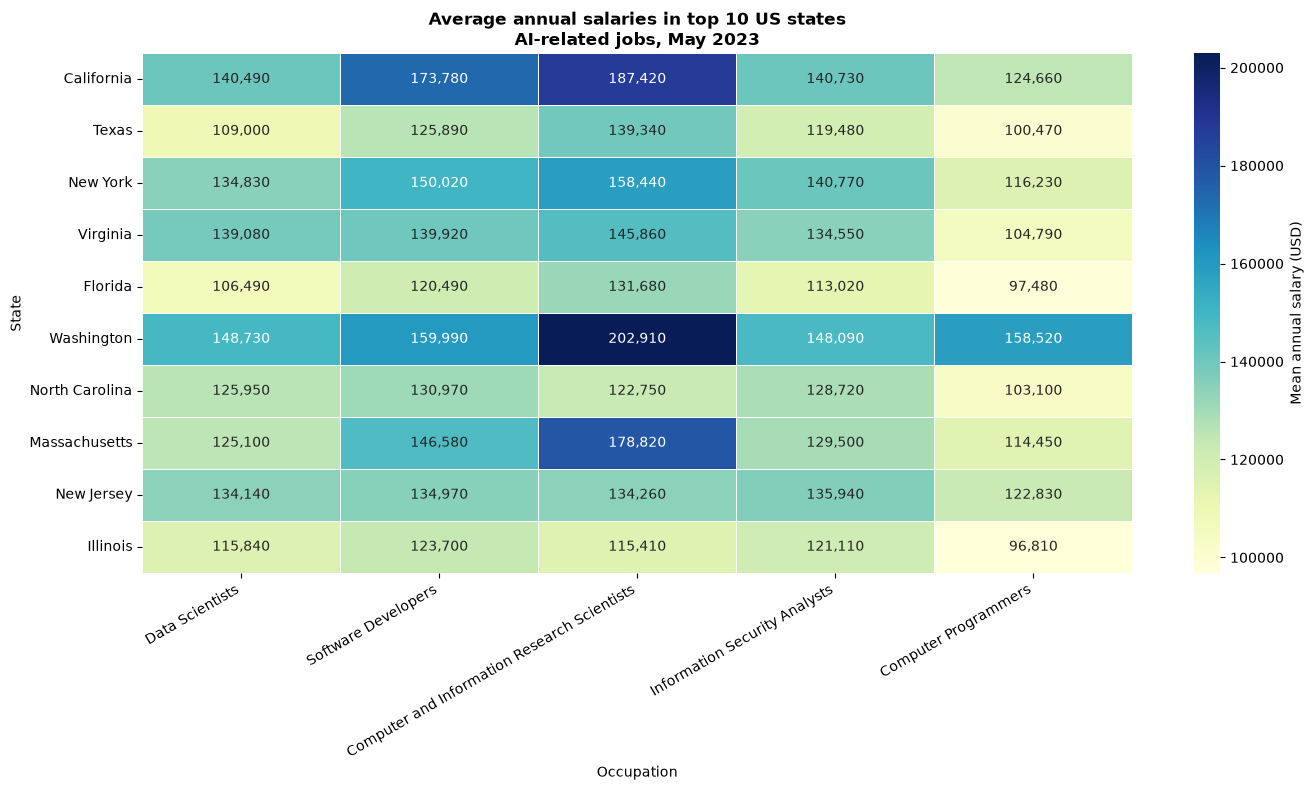

In [8]:
top_states = (
    state_data.groupby("AREA_TITLE")["TOT_EMP"]
    .sum(min_count=1)
    .nlargest(10)
    .index)

heatmap_data = state_data[
    state_data["AREA_TITLE"].isin(top_states)].pivot_table(
    index="AREA_TITLE",
    columns="OCC_TITLE",
    values="A_MEAN",
    aggfunc="first")

heatmap_data = heatmap_data.reindex(
    index=top_states,
    columns=occupations)

plt.figure(figsize=(14, 8))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Mean annual salary (USD)"})

plt.title(
    "Average annual salaries in top 10 US states\n"
    "AI-related jobs, May 2023",
    fontweight="bold")

plt.xlabel("Occupation")
plt.ylabel("State")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Visualisation 5 Average annual salaries in US States 

Objective: 

The plot map shows that average annual salaries comparison between different states in the US for five occupations related to AI and technology. From this I can see that which states offer higher salaries and where this salary differences are consistent across these jobs. I chose heatmap for the fifth visualisation because it allows me to compare numerical values across two categorical variables of states and occupation. The colour intensity shows that average annual salary is higher and lighter the colour means lower salaries. And salaries are also in numbers inside the cell making it easier to read it. This compared to the box plot shows overall distribution of state salaries however, the heatmap allows me to identify which state in the US have higher or lower salaries. 

Findings and what we can understand: 

The heatmap shows big differences in salaries in the US occupations. For example, Washington have the highest salary displayed in the heatmap in Computer and information research scientists at 202910 dollars. On the other hand, Illinois has the lowest in CIRS with 115410 dollars with difference of 87500 dollars. California has the highest average salary in Software developers at 173780 dollars while, Washington has the highest salary in Data Scientists at 148730 dollars. Washington also have highest salary in Information security analysts and computer programmer meaning Washington have the highest paying jobs on average. On the other hand, Illinois is the lowest average paying state. These results suggest that geographical location relates to annual earnings. 

In conclusion: 

The heatmap demonstrates that average annual salaries are different depending on where you are employed and what job you are working. Washington stands as the highest paying state in the United States in four of five occupations. The visualisation helps us understand more about the dataset and look with more fresh perspective in these five occupations with technological related jobs.

In [9]:
print("National records:", len(national_data))
print("State records:", len(state_data))

print("\nMissing values:")
print(filtered_data[["TOT_EMP", "A_MEAN"]].isna().sum())

print("\nDuplicate national occupations:")
print(national_data.duplicated(subset=["OCC_CODE"]).sum())

print("\nDuplicate state occupations:")
print(
    state_data.duplicated(subset=["AREA_TITLE", "OCC_CODE"]).sum())

National records: 5
State records: 246

Missing values:
TOT_EMP    25
A_MEAN     17
dtype: int64

Duplicate national occupations:
0

Duplicate state occupations:
0


This is the employment figures for 2022 and 2024 to compare with 2023 completely different dataset

In [10]:
for year in [2022, 2023, 2024]:
    file = f"all_data_M_{year}.xlsx"
    excel = pd.ExcelFile(file)
    print(year, excel.sheet_names)

2022 ['All May 2022 data', 'Field Descriptions', 'UpdateTime', 'Filler']
2023 ['All May 2023 data', 'Field Descriptions', 'UpdateTime', 'Filler']
2024 ['All May 2024 data', 'Field Descriptions', 'UpdateTime', 'Filler']


In [12]:
years = [2022, 2023, 2024]
historical_data = []

for year in years:
    data = pd.read_excel(
        f"all_data_M_{year}.xlsx",
        sheet_name=f"All May {year} data",
        usecols=["AREA_TITLE","NAICS","OCC_CODE","OCC_TITLE","O_GROUP","TOT_EMP"])
    data["NAICS"] = data["NAICS"].astype(str).str.strip()
    data["TOT_EMP"] = pd.to_numeric(data["TOT_EMP"], errors="coerce")
    data = data[
        (data["AREA_TITLE"] == "U.S.") &
        (data["NAICS"].isin(["0", "0.0", "000000"])) &
        (data["O_GROUP"] == "detailed") &
        (data["OCC_TITLE"].isin(occupations))].copy()
    data["Year"] = year 
    historical_data.append(data)

employment_trends = pd.concat(historical_data, ignore_index=True)
print(employment_trends[["Year", "OCC_TITLE", "TOT_EMP"]])

    Year                                     OCC_TITLE    TOT_EMP
0   2022                 Information Security Analysts   163690.0
1   2022  Computer and Information Research Scientists    33780.0
2   2022                          Computer Programmers   132740.0
3   2022                           Software Developers  1534790.0
4   2022                               Data Scientists   159630.0
5   2023                 Information Security Analysts   175350.0
6   2023  Computer and Information Research Scientists    35210.0
7   2023                          Computer Programmers   120370.0
8   2023                           Software Developers  1656880.0
9   2023                               Data Scientists   192710.0
10  2024                 Information Security Analysts   179430.0
11  2024  Computer and Information Research Scientists    38480.0
12  2024                          Computer Programmers   109870.0
13  2024                           Software Developers  1654440.0
14  2024  

In [18]:
employment_table = employment_trends.pivot_table(
    index="Year",
    columns="OCC_TITLE",
    values="TOT_EMP",
    aggfunc="sum")
employment_table = employment_table.reindex(
    index=[2022, 2023, 2024],
    columns=occupations)
print(employment_table)

OCC_TITLE  Data Scientists  Software Developers  \
Year                                              
2022              159630.0            1534790.0   
2023              192710.0            1656880.0   
2024              233440.0            1654440.0   

OCC_TITLE  Computer and Information Research Scientists  \
Year                                                      
2022                                            33780.0   
2023                                            35210.0   
2024                                            38480.0   

OCC_TITLE  Information Security Analysts  Computer Programmers  
Year                                                            
2022                            163690.0              132740.0  
2023                            175350.0              120370.0  
2024                            179430.0              109870.0  


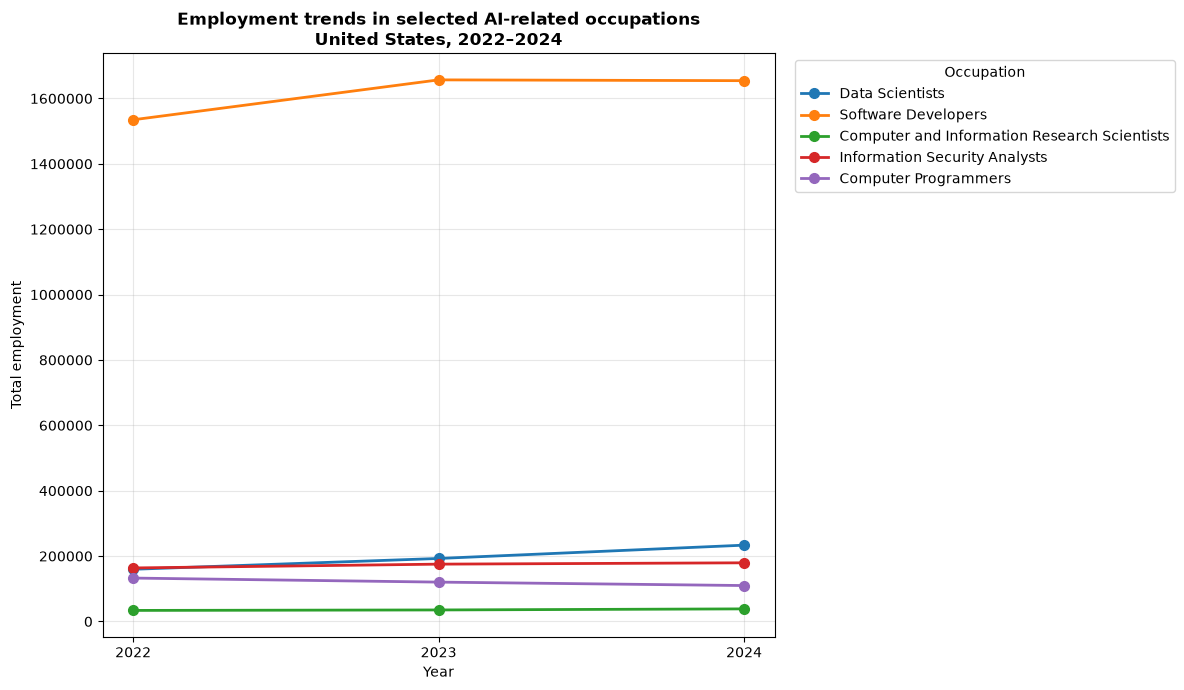

In [19]:
plt.figure(figsize=(12, 7))
for occupation in occupations:
    plt.plot(
        employment_table.index,
        employment_table[occupation],
        marker="o",
        linewidth=2,
        markersize=7,
        label=occupation)
plt.title(
    "Employment trends in selected AI-related occupations\n"
    "United States, 2022–2024",
    fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Total employment")
plt.xticks([2022, 2023, 2024])
plt.ticklabel_format(style="plain", axis="y")
plt.grid(alpha=0.3)
plt.legend(title="Occupation", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Employment trends 2022 to 2024

Objective of this visualisation is to find out the difference between years total employment in 2022, 2023 and 2024 in the US. This line chart indicates that employment have grown over the 3 years significantly.

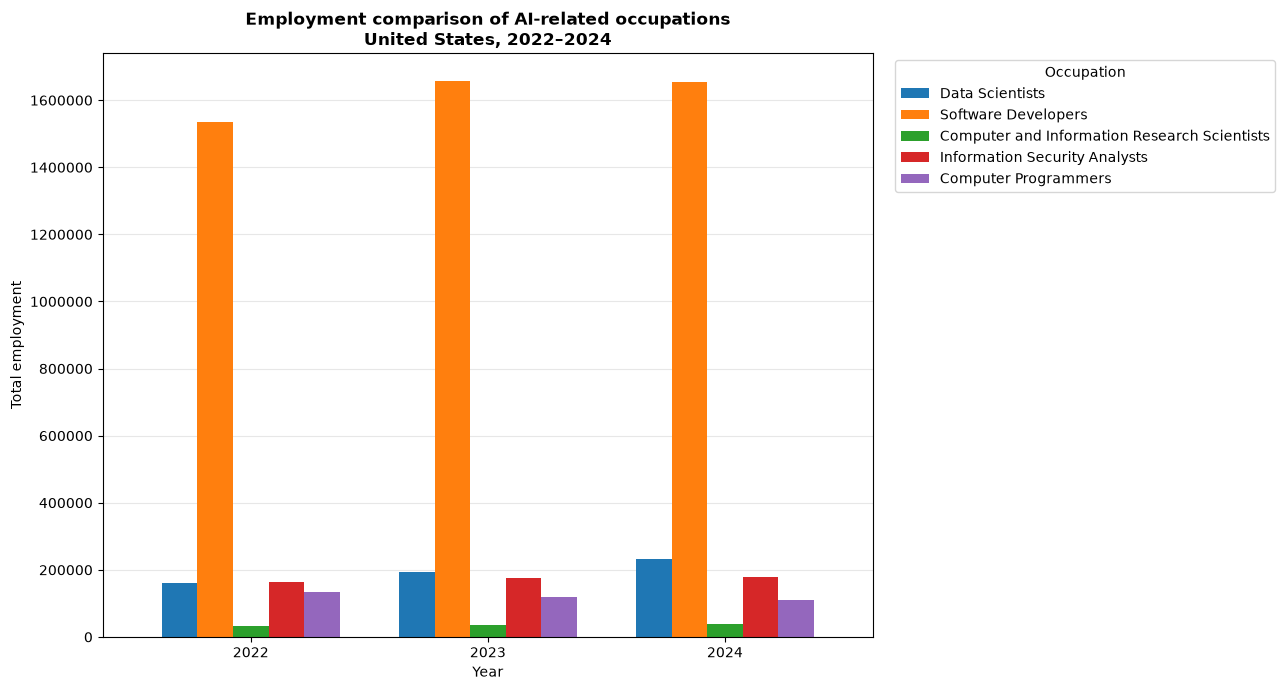

In [20]:
import matplotlib.pyplot as plt

ax = employment_table.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.75)
plt.title(
    "Employment comparison of AI-related occupations\nUnited States, 2022–2024",
    fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Total employment")
plt.xticks(rotation=0)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(axis="y", alpha=0.3)
plt.legend(
    title="Occupation",
    bbox_to_anchor=(1.02, 1),
    loc="upper left")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


### What we can understand

Software developers have been the most employed occupation throught out the years. While, Data scientist have the most growth of employment in this 3 years. On the other hand, Computer programmer saw the most decline in employees due to AI replacing the jobs. Because of software developer we cant see the numbers in more detailed lacking more clear understanding.

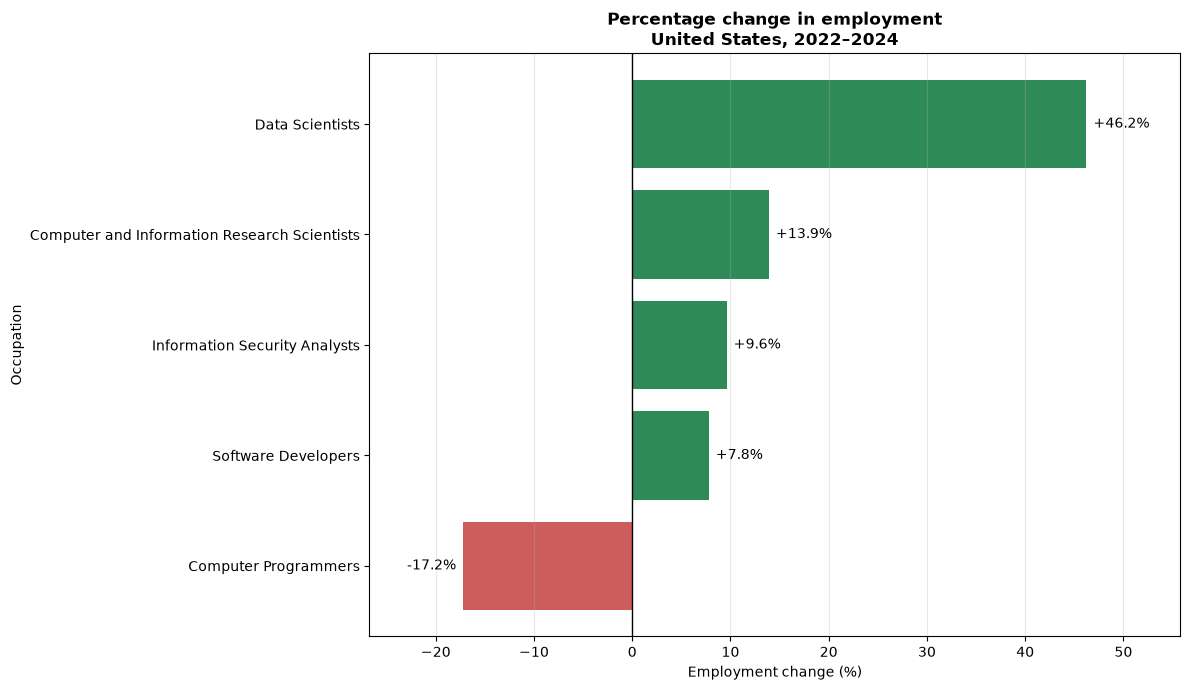

In [21]:
import matplotlib.pyplot as plt

percentage_change = (
    (employment_table.loc[2024] - employment_table.loc[2022]) / employment_table.loc[2022]) * 100

percentage_change = percentage_change.sort_values()
colors = [
    "seagreen" if value >= 0 else "indianred"
    for value in percentage_change]

plt.figure(figsize=(12, 7))
bars = plt.barh(
    percentage_change.index,
    percentage_change.values,
    color=colors)
plt.title(
    "Percentage change in employment\nUnited States, 2022–2024",
    fontweight="bold")

plt.xlabel("Employment change (%)")
plt.ylabel("Occupation")
plt.axvline(0, color="black", linewidth=1)
plt.grid(axis="x", alpha=0.3)

for bar, value in zip(bars, percentage_change.values):
    plt.annotate(
        f"{value:+.1f}%",
        (value, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center")
plt.margins(x=0.15)
plt.tight_layout()
plt.show()


###The chart explains

The chart shows that five jobs related to AI between 2022 to 2024. Data scientist have the highest growth with 46.2 percentage increase, followed by 13.9 percentage of computer and information research scientist. Smallest growth of percentage increase was 7.8 however, computer programmer have experienced decline of employment with 17.2 percentage making it only the job thats going down in number of workers. 

In conclusion, the four of the five employment increased in workers while one of them decreased in workers. This means that AI related jobs are on the rise slightly particularly data science.